In [1]:
import os
from dotenv import load_dotenv

# from typing import Annotated, List, Optional, Dict, Literal
# from typing_extensions import TypedDict
from typing import Literal, Optional
from pydantic import BaseModel, Field

from langchain_groq import ChatGroq
from langchain_google_genai import ChatGoogleGenerativeAI

from langgraph.prebuilt import create_react_agent as create_agent
# from langchain_core.tools import tool
# from langchain_core.language_models.chat_models import BaseChatModel
# from langchain_core.messages import HumanMessage, trim_messages
from langchain_core.messages import AIMessage, AnyMessage, HumanMessage, SystemMessage, ToolMessage


# from langgraph.types import Command
# from langgraph.graph import StateGraph, MessagesState, START, END

from shutil import which

def _ensure_java_on_path() -> None:
	if which("java") is not None:
		return
	for candidate in ("/opt/homebrew/opt/openjdk/bin", "/usr/local/opt/openjdk/bin", "/usr/bin"):
		if os.path.exists(os.path.join(candidate, "java")):
			os.environ["PATH"] = os.pathsep.join([candidate, os.environ.get("PATH", "")])
			return

_ensure_java_on_path()

from tools import check_text_spelling, analyze_agreement, analyze_capitalization, extract_citations, extract_connectives, validate_json_format

/Users/artur.oliveira/Documents/unicamp/mc959/multiagent-enem-scoring/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
/Users/artur.oliveira/Documents/unicamp/mc959/multiagent-enem-scoring/.venv/lib/python3.9/site-packages/google/api_core/_python_version_support.py:242: FutureWarning: You are using a non-supported Python version (3.9.6). Google will not post any further updates to google.api_core supporting this Python version. Please upgrade to the latest Python version, or at least Python 3.11, and then update google.api_core.
  warnings.warn(message, FutureWarning)
/Users/artur.oliveira/Documents/unicamp/mc959/multiagent-enem-scoring/.venv/lib/python3.9/site-packages/google/auth/__init__.py:54: FutureWarning: You are using a Python version 3.9 past its end of life. Google will update go

In [2]:
load_dotenv()
PROVIDER = os.getenv("PROVIDER")
GROQ_API_KEY = os.getenv("GROQ_API_KEY")
GEMINI_API_KEY = os.getenv("GEMINI_API_KEY")

MODELS = {
	"GROQ": {
		"LLM":"openai/gpt-oss-120b",
		"SLM":"qwen/qwen3.8-27b",
	},
	"GEMINI": {
		"LLM": "gemini-3.5-flash-lite",
		"SLM": "gemini-3.1-flash-lite"
	}
}

if PROVIDER.upper() in ['GOOGLE', 'GEMINI']:
	orchestrator_model = ChatGoogleGenerativeAI(model=MODELS['GEMINI']['LLM'], api_key=GEMINI_API_KEY, max_tokens=8192)
	specialist_model = ChatGoogleGenerativeAI(model=MODELS['GEMINI']['SLM'], api_key=GEMINI_API_KEY, max_tokens=8192)
	revisor_model = ChatGoogleGenerativeAI(model=MODELS['GEMINI']['LLM'], api_key=GEMINI_API_KEY, max_tokens=8192)
else:
	orchestrator_model = ChatGroq(model=MODELS['GROQ']['LLM'], temperature=0.5, api_key=GROQ_API_KEY, max_tokens=8192)
	specialist_model = ChatGroq(model=MODELS['GROQ']['SLM'], temperature=0.2, api_key=GROQ_API_KEY, max_tokens=8192)
	revisor_model = ChatGroq(model=MODELS['GROQ']['LLM'], temperature=0.2, api_key=GROQ_API_KEY, max_tokens=8192)

AttributeError: 'NoneType' object has no attribute 'upper'

## Supervisor Agent

In [3]:
AgentID = Literal['0', '1', '2', '3', '4', '5', '6']
CompetenceID = Literal['1', '2', '3', '4', '5']

### Especialist Agents

In [4]:
class Justification(BaseModel):
	excerpt: str = Field(description="Trecho com o erro identificado passível de dedução de nota")
	reason: str = Field(description="Explicação da dedução relacionada à rúbrica da Competência corrigida")

class CompetenceResponseFormat(BaseModel):
	"""
	Saída estruturada contendo a nota (0 a 200 intervalada por 40)
	e a justificativa de dedução das notas com o trecho respectivo
	"""
	grade: Literal[0, 40, 80, 120, 160, 200] = Field(description="Nota discretizada em intervalos de 40")
	justification: list[Justification] = Field(description="Justificativas de dedução de nota, com trecho e explicação")

class CompetenceEvaluation(CompetenceResponseFormat):
	competence_id: CompetenceID

#### 1st Competence Team

Competência I - Norma Culta

Avalia o domínio da modalidade escrita formal da língua portuguesa.<br/>
Analisa conhecimento das convenções de escrita, precisão gramatical, construção sintática e escolha vocabular.

Aspectos avaliados
- **convenções da escrita:** acentuação, ortografia, uso de hífen, emprego de letras maiúsculas e minúsculas e separação silábica (translineação)
- **gramaticais:** regência verbal e nominal, concordância verbal e nominal, tempos e modos verbais, pontuação, paralelismos sintático, morfológico e semântico, emprego de pronomes e crase
- **escolha de registro:** adequação à modalidade escrita formal, isto é, ausência de uso de registro informal e/ou de marcas de oralidade
- **escolha vocabular:** emprego de vocabulário preciso, o que significa que as palavras selecionadas são usadas em seu sentido correto e são apropriadas ao contexto em que aparecem

---

| Pontuação	| Justificativa	|
|-----------|---|
|200 pontos | Demonstra excelente domínio da modalidade escrita formal da língua portuguesa e de escolha de registro. Desvios gramaticais ou de convenções da escrita serão aceitos somente como excepcionalidade e quando não caracterizarem reincidência. |
|160 pontos	| Demonstra bom domínio da modalidade escrita formal da língua portuguesa e de escolha de registro, com poucos desvios gramaticais e de convenções da escrita. |
|120 pontos	| Demonstra domínio mediano da modalidade escrita formal da língua portuguesa e de escolha de registro, com alguns desvios gramaticais e de convenções da escrita. |
| 80 pontos	| Demonstra domínio insuficiente da modalidade escrita formal da língua portuguesa, com muitos desvios gramaticais, de escolha de registro e de convenções da escrita. |
| 40 pontos	| Demonstra domínio precário da modalidade escrita formal da língua portuguesa, de forma sistemática, com diversificados e frequentes desvios gramaticais, de escolha de registro e de convenções da escrita. |
| 0 ponto	| Demonstra desconhecimento da modalidade escrita formal da língua portuguesa. |

In [5]:
C1_SYS_PROMPT = "Avalie este trecho de acordo com a competência 1 do ENEM"
C1_SYS_PROMPT = "Responda apenas com a nota máxima e nada de justificativa"

C1_TOOLS = [check_text_spelling, analyze_agreement, analyze_capitalization]

C1_AGENT = create_agent(
	model=specialist_model,
	# tools=C1_TOOLS,
	system_prompt=C1_SYS_PROMPT,
	response_format=CompetenceResponseFormat
)

#### 2nd Competence Team

Competência II - Compreensão da Proposta e Repertório

Avalia a compreensão da proposta de redação e a aplicação de conceitos das várias áreas de conhecimento para desenvolver o tema, dentro dos limites estruturais do texto dissertativo-argumentativo. <br/>
Analisa a abordagem do tema, a adequação ao tipo textual e o uso de repertório sociocultural.

Aspectos avaliados
- **compreensão do tema:** abordagem completa do tema proposto, isto é, tanto do assunto geral quanto do recorte específico, sem tangenciá-lo nem fugir dele
- **tipo textual:** atendimento à estrutura dissertativo-argumentativa, com proposição (tese), argumentação (desenvolvimento) e conclusão, sem traços de outros tipos textuais (narração, descrição, etc.)
- **repertório sociocultural:** uso de informações, fatos, citações ou experiências vividas que contribuam como argumento para a discussão proposta. Para ser bem aproveitado, o repertório deve ser:
	1. **legitimado:** ancorado em área do conhecimento reconhecida e corretamente atribuído, e não baseado apenas nos textos motivadores
	2. **pertinente:** relacionado ao tema discutido
	3. **produtivo:** usado como argumento, com função argumentativa identificável e interpretado pelo participante, e não como "repertório de bolso", isto é, referência pronta, genérica e inserida apenas para demonstrar erudição
- **autoria:** ausência de cópia de trechos dos textos motivadores

---

| Pontuação | Justificativa |
|-----------|---|
| 200 pontos | Desenvolve o tema por meio de argumentação consistente, a partir de um repertório sociocultural produtivo, e apresenta excelente domínio do texto dissertativo-argumentativo. |
| 160 pontos | Desenvolve o tema por meio de argumentação consistente e apresenta bom domínio do texto dissertativo-argumentativo, com proposição, argumentação e conclusão. |
| 120 pontos | Desenvolve o tema por meio de argumentação previsível e apresenta domínio mediano do texto dissertativo-argumentativo, com proposição, argumentação e conclusão. |
| 80 pontos | Desenvolve o tema recorrendo à cópia de trechos dos textos motivadores ou apresenta domínio insuficiente do texto dissertativo-argumentativo, não atendendo à estrutura com proposição, argumentação e conclusão. |
| 40 pontos | Apresenta o assunto, tangenciando o tema, ou demonstra domínio precário do texto dissertativo-argumentativo, com traços constantes de outros tipos textuais. |
| 0 ponto | Fuga ao tema/não atendimento à estrutura dissertativo-argumentativa. Nestes casos, a redação recebe nota zero e é anulada. |

In [6]:
C2_SYS_PROMPT = "Avalie este trecho de acordo com a competência 2 do ENEM. O tema é 'Desafios para valorização do SUS'. Dê resposta curtíssima, máximo 10 palavras."
C2_SYS_PROMPT = "Responda apenas com a nota máxima e nada de justificativa"

C2_TOOLS = [extract_citations]

C2_AGENT = create_agent(
	model=specialist_model,
	# tools=C2_TOOLS,
	system_prompt=C2_SYS_PROMPT,
	response_format=CompetenceResponseFormat
)

#### 3rd Competence Team

Competência III - Seleção e Organização de Argumentos

Avalia como o participante seleciona, relaciona, organiza e interpreta informações, fatos, opiniões e argumentos em defesa de um ponto de vista. <br/>
Analisa a inteligibilidade do texto, isto é, sua coerência e a plausibilidade entre as ideias apresentadas, a partir do projeto de texto.

Aspectos avaliados
- **seleção de argumentos:** escolha de informações, fatos e opiniões pertinentes à defesa do ponto de vista, sem ideias irrelevantes, repetidas ou excessivas
- **relação de sentido entre as partes:** coerência entre introdução, desenvolvimento e conclusão, de modo que os argumentos convirjam para a defesa do ponto de vista
- **progressão temática:** encadeamento das ideias, em que cada parágrafo traz informações coerentes com o que foi discorrido anteriormente, sem repetições desnecessárias nem saltos temáticos
- **desenvolvimento dos argumentos:** explicitação, explicação ou exemplificação das informações (por meio de exemplos, dados, comparações, analogias, etc.), com a relevância das ideias e do ponto de vista explicitada
- **projeto de texto:** planejamento prévio que define quais argumentos serão mobilizados e em que ordem, o que se evidencia quando a introdução já delimita os argumentos que serão desenvolvidos
- **autoria:** seleção e interpretação próprias das informações, para além de reproduzir os argumentos dos textos motivadores

---

| Pontuação | Justificativa |
|-----------|---|
| 200 pontos | Apresenta informações, fatos e opiniões relacionados ao tema proposto, de forma consistente e organizada, configurando autoria, em defesa de um ponto de vista. |
| 160 pontos | Apresenta informações, fatos e opiniões relacionados ao tema, de forma organizada, com indícios de autoria, em defesa de um ponto de vista. |
| 120 pontos | Apresenta informações, fatos e opiniões relacionados ao tema, limitados aos argumentos dos textos motivadores e pouco organizados, em defesa de um ponto de vista. |
| 80 pontos | Apresenta informações, fatos e opiniões relacionados ao tema, mas desorganizados ou contraditórios e limitados aos argumentos dos textos motivadores, em defesa de um ponto de vista. |
| 40 pontos | Apresenta informações, fatos e opiniões pouco relacionados ao tema ou incoerentes e sem defesa de um ponto de vista. |
| 0 ponto | Apresenta informações, fatos e opiniões não relacionados ao tema e sem defesa de um ponto de vista. |

In [7]:
C3_SYS_PROMPT = "Avalie este trecho de acordo com a competência 3 do ENEM. O tema é 'Desafios para valorização do SUS'. Dê resposta curtíssima, máximo 10 palavras."
C3_SYS_PROMPT = "Responda apenas com a nota máxima e nada de justificativa"

C3_TOOLS = []

C3_AGENT = create_agent(
	model=specialist_model,
	tools=C3_TOOLS,
	prompt=C3_SYS_PROMPT,
	response_format=CompetenceResponseFormat
)

#### 4th Competence Team

Competência IV - Mecanismos Linguísticos

Avalia o conhecimento dos mecanismos linguísticos necessários para a construção da argumentação, isto é, a estruturação lógica e formal entre as partes do texto. <br/>
Analisa a coesão textual, ou seja, os recursos linguísticos que promovem o encadeamento das ideias entre orações, períodos e parágrafos.

Aspectos avaliados
- **estruturação dos parágrafos:** desenvolvimento de cada parágrafo a partir de uma ideia principal à qual se ligam ideias secundárias (por comparação, por causa e consequência, por exemplificação, por detalhamento, etc.), com articulação explícita entre um parágrafo e outro
- **estruturação dos períodos:** construção de períodos complexos, formados por duas ou mais orações, capazes de expressar relações de causa e consequência, contradição, temporalidade, comparação, conclusão, etc.
- **referenciação:** retomada de pessoas, coisas, lugares e fatos ao longo do texto por meio de pronomes, advérbios, artigos, sinônimos, antônimos, hipônimos, hiperônimos, expressões resumitivas, metafóricas ou metadiscursivas, e também de elipse
- **operadores argumentativos e conectores:** uso de preposições, conjunções, pronomes relativos, advérbios e locuções adverbiais que estabelecem relações lógicas e semânticas (igualdade, adversidade, causa, consequência, conclusão, etc.) entre orações, períodos e parágrafos
- **diversidade e adequação dos recursos coesivos:** variedade de recursos empregados e relação lógica adequada entre as ideias que eles conectam. A coesão não depende da mera presença de conectivos, e o uso excessivo ou formulaico deles não é critério de qualidade
- **inadequações a evitar:** ausência de articulação entre orações, frases e parágrafos, ausência de paragrafação, emprego de conector sem relação lógica com o contexto, e repetição ou substituição inadequada de palavras sem recorrer a recursos anafóricos

---

| Pontuação | Justificativa |
|-----------|---|
| 200 pontos | Articula bem as partes do texto e apresenta repertório diversificado de recursos coesivos. |
| 160 pontos | Articula as partes do texto, com poucas inadequações, e apresenta repertório diversificado de recursos coesivos. |
| 120 pontos | Articula as partes do texto, de forma mediana, com inadequações, e apresenta repertório pouco diversificado de recursos coesivos. |
| 80 pontos | Articula as partes do texto, de forma insuficiente, com muitas inadequações, e apresenta repertório limitado de recursos coesivos. |
| 40 pontos | Articula as partes do texto de forma precária. |
| 0 ponto | Não articula as informações. |

In [8]:
C4_SYS_PROMPT = "Avalie este trecho de acordo com a competência 4 do ENEM. O tema é 'Desafios para valorização do SUS'. Dê resposta curtíssima, máximo 10 palavras."
C4_SYS_PROMPT = "Responda apenas com a nota máxima e nada de justificativa"

C4_TOOLS = [extract_connectives]

C4_AGENT = create_agent(
	model=specialist_model,
	# tools=C4_TOOLS,
	system_prompt=C4_SYS_PROMPT,
	response_format=CompetenceResponseFormat
)

#### 5th Competence Team

Competência V - Proposta de Intervenção

Avalia a elaboração de uma proposta de intervenção para o problema abordado no texto, respeitando os direitos humanos. <br/>
Analisa se a proposta está relacionada ao tema, se é detalhada e se está articulada à discussão desenvolvida ao longo da redação.

Aspectos avaliados
- **presença de proposta de intervenção:** indicação clara de uma ação voltada a enfrentar o problema discutido no texto. Apenas constatar a falta de uma ação ou de um projeto, ou apresentar soluções vagas, genéricas ou inviáveis, não configura proposta de intervenção
- **elementos da proposta:** a proposta é construída a partir da resposta a perguntas como:
	1. **ação:** o que é possível propor como solução para o problema?
	2. **agente:** quem deve executar a ação (governo, ministérios, escolas, mídia, sociedade civil, etc.)?
	3. **meio/modo de execução:** como a ação será posta em prática?
	4. **finalidade/efeito:** qual é o efeito esperado da ação?
	5. **detalhamento:** que outras informações são relevantes para a proposta (exemplificação, explicação, etc.)?
- **relação com o tema:** a proposta responde ao problema específico apresentado no tema, e não apenas ao assunto geral
- **articulação com a discussão:** a proposta é coerente com o ponto de vista e com os argumentos desenvolvidos, respondendo aos problemas abordados ao longo do texto
- **respeito aos direitos humanos:** a proposta não pode violar direitos humanos, como a defesa de tortura, mutilação, execução sumária, "justiça com as próprias mãos" ou qualquer forma de violência ou discriminação por raça, etnia, gênero, credo, opinião política, condição física, origem geográfica ou socioeconômica

> #### Atenção!
> Propostas que desrespeitem os direitos humanos receberão nota 0 (zero) na Competência V.

---

| Pontuação | Justificativa |
|-----------|---|
| 200 pontos | Elabora muito bem proposta de intervenção, detalhada, relacionada ao tema e articulada à discussão desenvolvida no texto. |
| 160 pontos | Elabora bem proposta de intervenção relacionada ao tema e articulada à discussão desenvolvida no texto. |
| 120 pontos | Elabora, de forma mediana, proposta de intervenção relacionada ao tema e articulada à discussão desenvolvida no texto. |
| 80 pontos | Elabora, de forma insuficiente, proposta de intervenção relacionada ao tema, ou não articulada com a discussão desenvolvida no texto. |
| 40 pontos | Apresenta proposta de intervenção vaga, precária ou relacionada apenas ao assunto. |
| 0 ponto | Não apresenta proposta de intervenção ou apresenta proposta não relacionada ao tema ou ao assunto. |

In [9]:
C5_SYS_PROMPT = "Avalie este trecho de acordo com a competência 5 do ENEM. O tema é 'Desafios para valorização do SUS'. Dê resposta curtíssima, máximo 10 palavras."
C5_SYS_PROMPT = "Responda apenas com a nota máxima e nada de justificativa"

C5_TOOLS = []

C5_AGENT = create_agent(
	model=specialist_model,
	tools=C5_TOOLS,
	prompt=C5_SYS_PROMPT,
	response_format=CompetenceResponseFormat
)

---

In [10]:
class CompetenceReview(BaseModel):
	approved: bool = Field(description="True se nota e justificativa estão coerentes com a rubrica e com os trechos citados")
	rejection_reason: str | None = Field(default=None, description="Falha detectada; obrigatório se approved=False")

class ReviewResponseFormat(BaseModel):
	"""
	Saída estruturada do revisor contendo o status (APROVADO ou REVISAO)
	e a justificativa da decisão se não for aprovado, mapeados por competência
	"""
	reviews: dict[CompetenceID, CompetenceReview]

In [11]:
REVISOR_SYS_PROMPT = "TODO: prompt do revisor (LLM-as-a-judge)"
REVISOR_SYS_PROMPT = "Apenas aprove tudo"
SUPERVISOR_SYS_PROMPT = "TODO: prompt do supervisor (relatório final didático)"
SUPERVISOR_SYS_PROMPT = "Gere um feedback curto, 10 palavras no máximo"

REVISOR_AGENT = create_agent(
	model=revisor_model,
	system_prompt=REVISOR_SYS_PROMPT,
	response_format=ReviewResponseFormat,
)
REVISOR_ID = '6'

SUPERVISOR_AGENT = create_agent(
	model=orchestrator_model,
	system_prompt=SUPERVISOR_SYS_PROMPT,
)
SUPERVISOR_ID = '0'

In [12]:
from langgraph.graph.state import CompiledStateGraph
from IPython.display import Image, display


def display_graph(graph: CompiledStateGraph) -> None:
	"""Renderiza o grafo compilado como imagem PNG."""
	display(Image(graph.get_graph().draw_mermaid_png()))

In [13]:
import json, operator
from typing import TypedDict, Annotated, Any
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send
from time import time_ns as now

MAX_REVISIONS = 2

def merge_dicts(a, b):
	"""Sobrescreve por chave. Usado quando só importa o valor mais recente."""
	return {**(a or {}), **(b or {})}

def concat_lists_in_dict(a, b):
	"""Concatena as listas por chave. Usado para históricos."""
	res = {key: list(val) for key, val in (a or {}).items()}
	for key, val in (b or {}).items():
		res.setdefault(key, []).extend(val)
	return res

class UsageStatistics(BaseModel):
	input_tokens: int
	output_tokens: int
	latency: int

class ScoringState(TypedDict, total=False):
	prompt: str
	essay: str
	scores: Annotated[dict[CompetenceID, CompetenceEvaluation], merge_dicts]
	history: Annotated[dict[CompetenceID, list[int]], concat_lists_in_dict]
	attempts: Annotated[dict[CompetenceID, int], merge_dicts]
	approved: Annotated[dict[CompetenceID, bool], merge_dicts]
	critiques: Annotated[dict[CompetenceID, list[str]], concat_lists_in_dict]
	usage: Annotated[dict[AgentID, list[UsageStatistics]], concat_lists_in_dict]
	feedback: str

class ScoringInput(TypedDict):
	prompt: str
	essay: str

class ScoringOutput(TypedDict):
	feedback: str
	scores: dict[CompetenceID, CompetenceEvaluation]
	usage: dict[AgentID, UsageStatistics]

In [14]:
def getUsage(result: dict, latency: int) -> UsageStatistics:
	ai_messages = [m for m in result['messages'] if isinstance(m, AIMessage)] or []
	return UsageStatistics(
		input_tokens=sum((m.usage_metadata or {}).get('input_tokens', 0) for m in ai_messages),
		output_tokens=sum((m.usage_metadata or {}).get('output_tokens', 0) for m in ai_messages),
		latency=latency
	)

In [15]:
specialist_team = {'1': C1_AGENT, '2': C2_AGENT, '3': C3_AGENT, '4': C4_AGENT, '5': C5_AGENT}

class SpecialistInput(TypedDict):
	competence_id: CompetenceID
	prompt: str
	essay: str
	attempt: int
	previous: Optional[CompetenceEvaluation]
	critiques: Optional[list[str]]

def distribute(state: ScoringState) -> list[Send]:
	return [
		Send(
			'specialist',
			SpecialistInput(
				competence_id=specialist,
				prompt=state['prompt'],
				essay=state['essay'],
				attempt=1
			)
		)
		for specialist in specialist_team.keys()
	]

def specialist_node(data: SpecialistInput) -> dict:
	specialist = data['competence_id']

	messages = []
	if data['attempt'] > 1 and len(data.get('critiques', [])) > 0:
		messages.append(SystemMessage(data['critiques'][-1])) # TODO: prompt de revisão da competência + data['previous'] --> talvez ter que mandar como humanMessage
	messages.append(HumanMessage(f"Tema:\n{data['prompt']}\n\nRedação:\n{data['essay']}"))

	before = now()
	result = specialist_team[specialist].invoke({'messages': messages}, {'recursion_limit': 50})
	after = now()

	answer: CompetenceResponseFormat = result['structured_response']
	evaluation = CompetenceEvaluation(competence_id=specialist, **answer.model_dump())

	return {
		'scores':   {specialist: evaluation},
		'history':  {specialist: [evaluation.grade]},
		'attempts': {specialist: data['attempt']},
		'approved': {specialist: False},
		'usage':    {specialist: [getUsage(result, after - before)]}
	}

def revisor_node(state: ScoringState) -> dict:
	approved = state.get('approved', {})
	attempts = state.get('attempts', {})
	pending = {s: e for s, e in state['scores'].items() if not approved.get(s, False) and attempts.get(s, 0) < MAX_REVISIONS+1}
	if not pending:
		return {}

	data = {
		'prompt': state['prompt'],
		'essay': state['essay'],
		'pending_scores': pending
	}

	before = now()
	result = REVISOR_AGENT.invoke({'messages': HumanMessage(f"Revise as avaliações de cada especialista: {data}")}, {'recursion_limit': 10})
	after = now()

	review: dict[CompetenceID, CompetenceReview] = result['structured_response'].reviews
	
	return {
		'approved': {s: review.get(s, {}).approved for s in specialist_team.keys()},
		'critiques': {s: review.get(s, {}).rejection_reason for s in specialist_team.keys() if not review.get(s, {}).approved},
		'usage': {REVISOR_ID: [getUsage(result, after - before)]}
	}

def review_decider(state: ScoringState) -> Literal['supervisor'] | list[Send]:
	veredicts = {s: v for s, v in state.get('approved', {}).items()}
	if all(veredicts.values()):
		return 'supervisor'

	rejected = [s for s, v in veredicts.items() if not v]
	if rejected:
		return [
			Send(
				'specialist',
				SpecialistInput(
					competence_id=specialist,
					prompt=state['prompt'],
					essay=state['essay'],
					attempt=state['attempts'][specialist]+1,
					previous=state.get('scores', {}).get(specialist, {}),
					critiques=state.get('critiques', {}).get(specialist, [])
				)
			)
			for specialist in rejected if state['attempts'][specialist] < MAX_REVISIONS+1
		]

	return 'supervisor'

def supervisor_node(state: ScoringState) -> dict:
	final_grade = sum(e.grade for e in state['scores'].values())

	data = {
		'prompt': state['prompt'],
		'essay': state['essay'],
		'scores': state['scores']
	}

	before = now()
	result = SUPERVISOR_AGENT.invoke({'messages': HumanMessage(f"Gere um feedback: {data}")}, {'recursion_limit': 10})
	after = now()

	feedback = result['messages'][-1].content[0]['text']

	return {
		'usage': {SUPERVISOR_ID: [getUsage(result, after - before)]},
		'feedback':
		f'''
			Nota Final: {final_grade}
			Nota por Competência:
				- Competência I:	{state['scores']['1'].grade:>3}
				- Competência II:	{state['scores']['2'].grade:>3}
				- Competência III:	{state['scores']['3'].grade:>3}
				- Competência IV:	{state['scores']['4'].grade:>3}
				- Competência V:	{state['scores']['5'].grade:>3}

			Feedback: {feedback}
		'''
	}

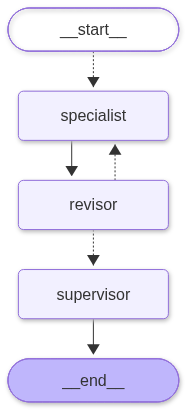

In [16]:
builder = StateGraph(ScoringState, input_schema=ScoringInput, output_schema=ScoringOutput)

builder.add_node('specialist', specialist_node)
builder.add_node('revisor', revisor_node)
builder.add_node('supervisor', supervisor_node)

builder.add_conditional_edges(START, distribute, ['specialist'])
builder.add_edge('specialist', 'revisor')
builder.add_conditional_edges('revisor', review_decider, ['specialist', 'supervisor'])
builder.add_edge('supervisor', END)

enem_scoring = builder.compile()

display_graph(enem_scoring)

In [17]:
t0 = now()
out = enem_scoring.invoke(
	{'prompt': 'Desafios para valorização do SUS no Brasil', 'essay': 'REDACAO_DE_TESTE'},
	{'max_concurrency': 5},
)
elapsed = now() - t0

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.
Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.
Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


In [18]:
print(f"{float(elapsed)/1e9:.3f} segundos")

41.050 segundos


In [19]:
print(json.dumps(out, default=lambda o: o.model_dump(), indent=2, ensure_ascii=False))

{
  "feedback": "\n\t\t\tNota Final: 1000\n\t\t\tNota por Competência:\n\t\t\t\t- Competência I:\t200\n\t\t\t\t- Competência II:\t200\n\t\t\t\t- Competência III:\t200\n\t\t\t\t- Competência IV:\t200\n\t\t\t\t- Competência V:\t200\n\n\t\t\tFeedback: Nota máxima! Redação excelente, coesa e perfeitamente argumentada. Parabéns!\n\t\t",
  "scores": {
    "1": {
      "grade": 200,
      "justification": [],
      "competence_id": "1"
    },
    "2": {
      "grade": 200,
      "justification": [],
      "competence_id": "2"
    },
    "3": {
      "grade": 200,
      "justification": [],
      "competence_id": "3"
    },
    "4": {
      "grade": 200,
      "justification": [],
      "competence_id": "4"
    },
    "5": {
      "grade": 200,
      "justification": [],
      "competence_id": "5"
    }
  },
  "usage": {
    "1": [
      {
        "input_tokens": 39,
        "output_tokens": 20,
        "latency": 18191930818
      }
    ],
    "2": [
      {
        "input_tokens": 39,
      